In [21]:
# %load_ext autoreload
%reload_ext autoreload
%autoreload 2

In [22]:
#!/usr/bin/env python3

import gtsam
import gtsam_unstable
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
%matplotlib widget
import numpy as np
np.set_printoptions(linewidth=np.inf, suppress=True)
import copy
import time
from pathlib import Path
import open3d as o3d
from scipy.spatial import KDTree
from dataclasses import asdict
import yaml
import pickle

# Local imports
from common.customTypes import DecisionType
import common.FGVizHelpers as fgtools
from params.params import Params
from multiSession.SessionManager import SessionManager

from sparcification.NFR import GraphSparsification
from rosBagRead.readFromRosbags import ReadTopicsFromRosbag
from common.groundTruthLoader import GroundTruthLoader



# Timing Comparison Between Dense and Approximate Marginalization

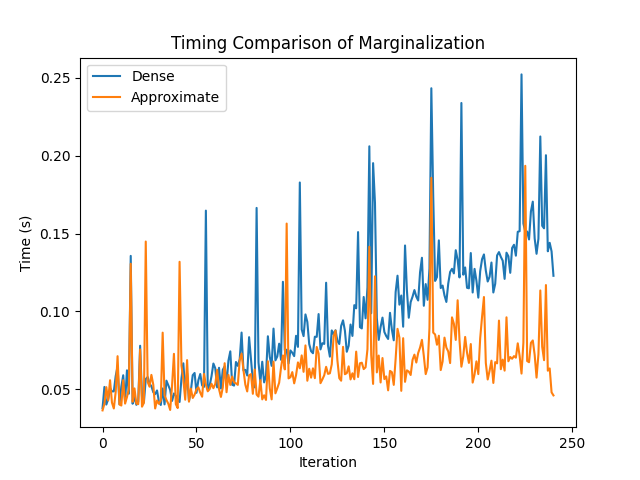

In [23]:
# Load timing pickle data and plot
with open("../results/nc_tests/quad-medium_cov_current_pose_eval/update_timing_dense.pkl", "rb") as f:
    timing_data_dense = pickle.load(f)

with open("../results/nc_tests/quad-medium_cov_current_pose_eval/update_timing_approx.pkl", "rb") as f:
    timing_data_approx = pickle.load(f)

fig, ax = plt.subplots()
ax.plot(timing_data_dense, label="Dense")
ax.plot(timing_data_approx, label="Approximate")
ax.set_xlabel("Iteration")
ax.set_ylabel("Time (s)")
ax.set_title("Timing Comparison of Marginalization")
ax.legend()


# Comparison of Determinants of Covariance for Dense and Approximate Marginalizations

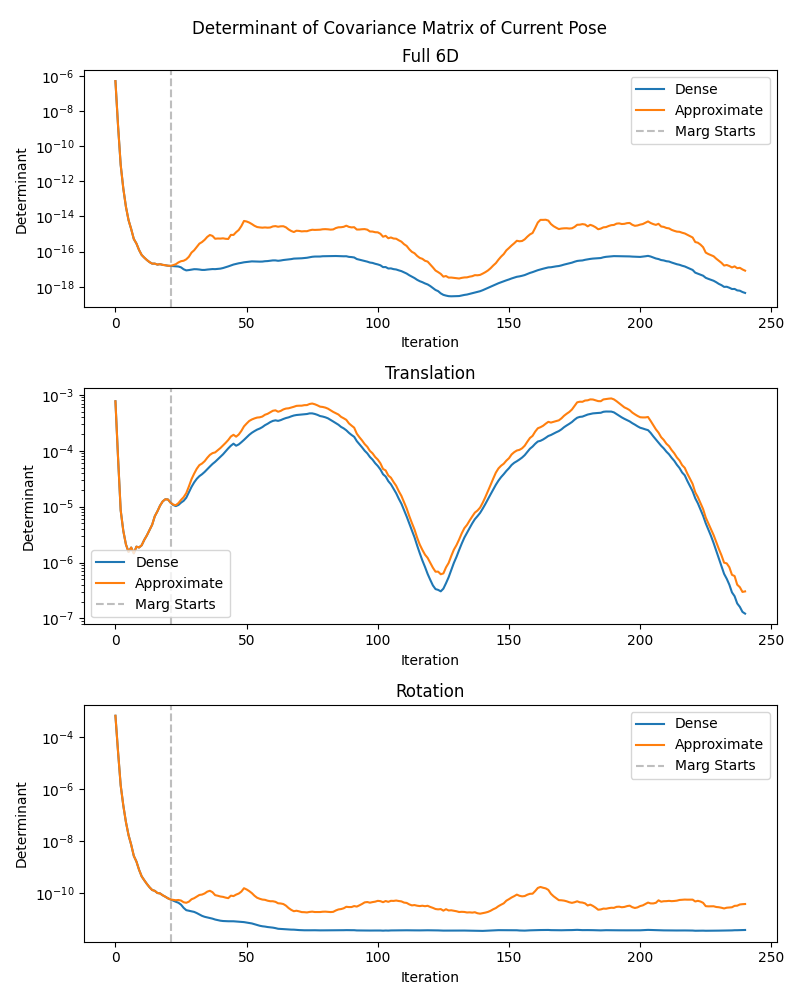

In [24]:
# Plot determinant of covariance matrices

with open("../results/nc_tests/quad-medium_cov_current_pose_eval/cov_of_currentPoses_dense.pkl", "rb") as f:
    cov_data_dense = np.asarray(pickle.load(f))

with open("../results/nc_tests/quad-medium_cov_current_pose_eval/cov_of_currentPoses_approx.pkl", "rb") as f:
    cov_data_approx = np.asarray(pickle.load(f))

det_full_dense = np.linalg.det(cov_data_dense)
det_full_approx = np.linalg.det(cov_data_approx)

det_trans_dense = np.linalg.det(cov_data_dense[:, 3:, 3:])
det_trans_approx = np.linalg.det(cov_data_approx[:, 3:, 3:])

det_rot_dense = np.linalg.det(cov_data_dense[:, :3, :3])
det_rot_approx = np.linalg.det(cov_data_approx[:, :3, :3])

det_dense = [det_full_dense, det_trans_dense, det_rot_dense]
det_approx = [det_full_approx, det_trans_approx, det_rot_approx]

fig, ax = plt.subplots(3, 1, figsize=(8, 10))
titles = ["Full 6D", "Translation", "Rotation"]

for i in range(3):
    ax[i].set_yscale("log")
    ax[i].plot(det_dense[i], label="Dense")
    ax[i].plot(det_approx[i], label="Approximate")
    ax[i].axvline(21, linestyle="--", color="tab:gray", alpha=0.5, label="Marg Starts")
    ax[i].set_title(titles[i])
    ax[i].set_xlabel("Iteration")
    ax[i].set_ylabel("Determinant")
    ax[i].legend()

plt.suptitle("Determinant of Covariance Matrix of Current Pose")
plt.tight_layout()

## Timing Plots For Each Decision Policy

In [25]:
DecisionType.NONE
dt.name == DecisionType.RELATIVE_COVARIANCE.name

True

Skipping None
DISTANCE: 204
OVERLAP: 204
INLIER_RATIO: 204
INLIER_RMSE: 204
TWO_STEP_VALIDATION: 204
RELATIVE_COVARIANCE: 204


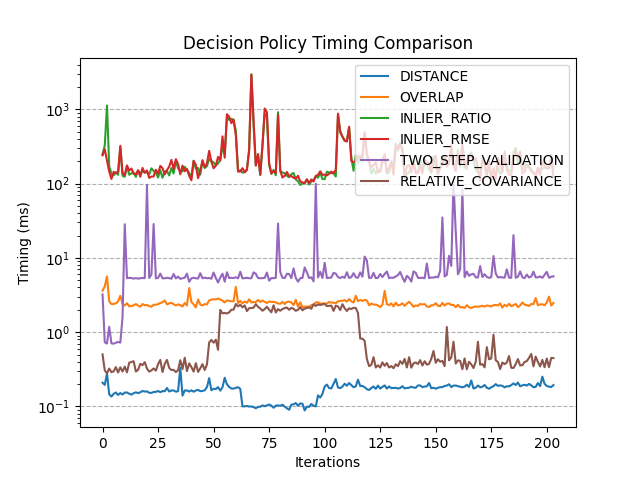

In [26]:
mainDir = Path("/home/benb/blocklio/python/results/nc/quad-hard_prior_quad-medium_prior_quad-easy")

timing_data: dict[str, np.ndarray] = {}
figName = "Timing Decision Policy"
plt.close(figName)
plt.figure(figName)
for dt in DecisionType:
    if dt.name == DecisionType.NONE.name:
        print("Skipping None")
        continue
    tmpPath = mainDir / dt.name / "timeToCalcMetricsAndDecision.txt"
    if not tmpPath.is_file():
        continue

    timing_data[dt.name] = np.loadtxt(tmpPath)
    print(f"{dt.name}: {timing_data[dt.name].size}")
    plt.plot(timing_data[dt.name] * 1e3, label=dt.name)

plt.yscale("log")
plt.xlabel("Iterations")
plt.ylabel("Timing (ms)")
plt.title("Decision Policy Timing Comparison")
plt.legend(loc="upper right")
plt.grid(axis='y', linestyle='--')


